In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

In [2]:
df = pd.read_csv('orders.csv')
df.head()

,order_id,customer_id,order_date,order_status,payment_method,channel,promo_code,shipping_city
0,O00140,C0112,06/09/2025,Complted,Debit Card,web,PROMO19,Chennai
1,O00225,C0066,10/14/2025,completed,NetBanking,web,NaN,Delhi
2,O00188,C0082,10/24/2024,PENDING,COD,APP,NaN,Hyderabad
3,O00183,C0114,30/07/2024,Pending,UPI,app,NaN,Ahmedabad
4,O00233,C0078,02/26/2025,completed,Credit Card,web,PROMO17,Hyderabad


In [3]:
df.shape

(323, 8)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 323 entries, 0 to 322
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   order_id        323 non-null    str  
 1   customer_id     323 non-null    str  
 2   order_date      323 non-null    str  
 3   order_status    323 non-null    str  
 4   payment_method  323 non-null    str  
 5   channel         323 non-null    str  
 6   promo_code      95 non-null     str  
 7   shipping_city   323 non-null    str  
dtypes: str(8)
memory usage: 20.3 KB


In [5]:
df.isnull().sum()

order_id            0
customer_id         0
order_date          0
order_status        0
payment_method      0
channel             0
promo_code        228
shipping_city       0
dtype: int64

In [6]:
print(df.duplicated().sum())
print(df['order_id'].duplicated().sum())
df[df['order_id'].duplicated(keep=False)].sort_values('order_id')

3
3


,order_id,customer_id,order_date,order_status,payment_method,channel,promo_code,shipping_city
234,O00012,C0050,10/06/2025,Complted,Debit Card,Web,NaN,Chennai
319,O00012,C0050,10/06/2025,Complted,Debit Card,Web,NaN,Chennai
254,O00108,C0129,13-Feb-2025,COMPLETE,COD,In-store,PROMO19,Lucknow
270,O00108,C0129,13-Feb-2025,COMPLETE,COD,In-store,PROMO19,Lucknow
83,O00170,C0002,09/11/2024,COMPLETE,Credit Card,app,PROMO2,Pune
302,O00170,C0002,09/11/2024,COMPLETE,Credit Card,app,PROMO2,Pune


In [7]:
for col in ['order_status', 'channel', 'payment_method', 'shipping_city']:
    print(df[col].value_counts())
    print()

order_status
Complted     46
completed    45
COMPLETE     42
Completed    34
Returned     31
returned     29
pending      23
PENDING      16
Pending      14
cancelled    12
Canceled     12
Cancelled    10
Cancled       9
Name: count, dtype: int64

channel
app         48
App         36
APP         34
web         33
Store       31
store       31
WEB         29
Web         28
In-store    28
Instore     25
Name: count, dtype: int64

payment_method
COD            72
Credit Card    68
UPI            64
Debit Card     63
NetBanking     56
Name: count, dtype: int64

shipping_city
Lucknow      40
Pune         38
Hyderabad    35
Mumbai       35
Jaipur       32
Kolkata      32
Chennai      30
Bangalore    30
Ahmedabad    26
Delhi        25
Name: count, dtype: int64



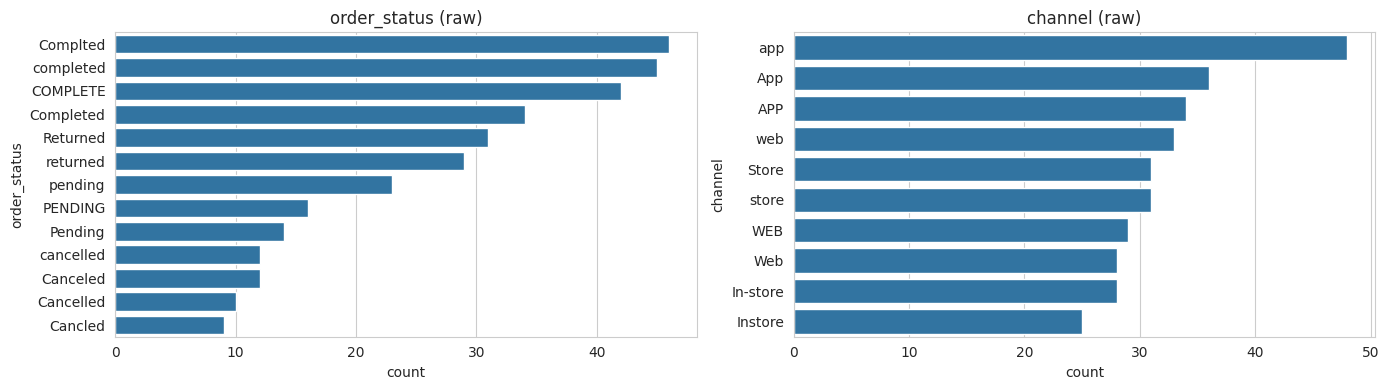

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(data=df, y='order_status', order=df['order_status'].value_counts().index, ax=ax[0])
sns.countplot(data=df, y='channel', order=df['channel'].value_counts().index, ax=ax[1])
ax[0].set_title('order_status (raw)')
ax[1].set_title('channel (raw)')
plt.tight_layout()
plt.show()

In [9]:
df['promo_code'].value_counts(dropna=False).head(10)

promo_code
NaN        228
PROMO19      9
PROMO4       9
PROMO9       8
PROMO1       8
PROMO17      7
PROMO10      6
PROMO5       5
PROMO16      5
PROMO11      4
Name: count, dtype: int64

In [10]:
df['order_date'].sample(12, random_state=5)

288     12/05/2021
127     23/08/2025
278     22/10/2024
261     06/22/2025
83      09/11/2024
42     26-Feb-2025
132     2024-10-03
47      03/03/2024
60      13/04/2025
257    05-Jan-2024
185     05/10/2024
320     02/06/2025
Name: order_date, dtype: str

In [11]:
customers = pd.read_csv('customers_clean.csv', parse_dates=['signup_date'])
id_map = pd.read_csv('customer_id_map.csv')
items = pd.read_csv('order_items.csv')
print(sorted(set(df['customer_id']) - set(customers['customer_id']) - set(id_map['customer_id'])))
print(df['customer_id'].isin(id_map['customer_id']).sum())
print(len(set(df['order_id']) - set(items['order_id'])))

['C9091', 'C9115', 'C9195', 'C9272', 'C9331', 'C9356', 'C9374', 'C9423', 'C9433', 'C9440', 'C9589', 'C9687', 'C9701', 'C9795', 'C9946']
14
1


In [12]:
def parse_date(x):
    if pd.isna(x):
        return pd.NaT
    x = str(x).strip()
    if x == '' or x.lower() == 'unknown':
        return pd.NaT
    if '/' in x:
        a, b, c = [int(i) for i in x.split('/')]
        if a > 12:
            return pd.Timestamp(year=c, month=b, day=a)
        if b > 12:
            return pd.Timestamp(year=c, month=a, day=b)
        return pd.Timestamp(year=c, month=b, day=a)
    if len(x) == 10 and x[4] == '-':
        return pd.to_datetime(x, format='%Y-%m-%d')
    return pd.to_datetime(x, format='%d-%b-%Y')


def is_ambiguous(x):
    if pd.isna(x) or '/' not in str(x):
        return False
    a, b, c = [int(i) for i in str(x).split('/')]
    return a <= 12 and b <= 12 and a != b

In [13]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(before, '->', len(df))
df['order_id'].duplicated().sum()

323 -> 320


np.int64(0)

In [14]:
status_map = {'complted': 'Completed', 'completed': 'Completed', 'complete': 'Completed',
              'returned': 'Returned', 'pending': 'Pending',
              'cancelled': 'Cancelled', 'canceled': 'Cancelled', 'cancled': 'Cancelled'}
df['order_status'] = df['order_status'].str.strip().str.lower().map(status_map)
print(df['order_status'].isnull().sum())
df['order_status'].value_counts()

0


order_status
Completed    164
Returned      60
Pending       53
Cancelled     43
Name: count, dtype: int64

In [15]:
channel_map = {'web': 'Web', 'app': 'App', 'store': 'Store', 'in-store': 'Store', 'instore': 'Store'}
df['channel'] = df['channel'].str.strip().str.lower().map(channel_map)
print(df['channel'].isnull().sum())
df['channel'].value_counts()

0


channel
App      117
Store    114
Web       89
Name: count, dtype: int64

In [16]:
df['payment_method'] = df['payment_method'].str.strip()
df['shipping_city'] = df['shipping_city'].str.strip().str.title()
df['promo_code'] = df['promo_code'].replace(['NA', 'N/A', 'None', 'null', ''], np.nan)
df['promo_code'] = df['promo_code'].str.strip().str.upper()
df['has_promo'] = df['promo_code'].notna()
df['has_promo'].value_counts()

has_promo
False    227
True      93
Name: count, dtype: int64

In [17]:
df['order_ambiguous'] = df['order_date'].apply(is_ambiguous)
df['order_date'] = df['order_date'].apply(parse_date)
print(df['order_ambiguous'].sum())
df['order_date'].describe()

63


count                    320
mean     2024-11-05 09:27:00
min      2020-10-29 00:00:00
25%      2024-06-19 18:00:00
50%      2024-11-14 00:00:00
75%      2025-05-07 06:00:00
max      2025-12-01 00:00:00
Name: order_date, dtype: object

In [18]:
print(df['order_date'].dt.year.value_counts().sort_index())
df['date_outlier'] = df['order_date'] < pd.Timestamp('2024-01-01')
df[df['date_outlier']][['order_id', 'customer_id', 'order_date', 'order_status']]

order_date
2020      2
2021      2
2022      2
2024    175
2025    139
Name: count, dtype: int64


,order_id,customer_id,order_date,order_status
157,O00220,C0031,2022-02-19,Pending
238,O00205,C0121,2021-09-13,Returned
248,O00001,C0033,2022-10-05,Completed
287,O00048,C0069,2021-05-12,Completed
290,O00234,C0037,2020-10-29,Returned
301,O00153,C0065,2020-12-25,Completed


In [19]:
df['customer_id'] = df['customer_id'].replace(dict(zip(id_map['customer_id'], id_map['master_id'])))
df['customer_orphan'] = ~df['customer_id'].isin(customers['customer_id'])
print(df['customer_orphan'].sum())
df[df['customer_orphan']].head()

15


,order_id,customer_id,order_date,order_status,payment_method,channel,promo_code,shipping_city,has_promo,order_ambiguous,date_outlier,customer_orphan
46,O00101,C9115,2025-04-12,Returned,NetBanking,Store,PROMO16,Hyderabad,True,True,False,True
66,O00127,C9374,2024-06-06,Completed,Credit Card,Store,NaN,Delhi,False,False,False,True
86,O00037,C9195,2025-01-27,Cancelled,UPI,App,PROMO4,Chennai,True,False,False,True
98,O00125,C9356,2024-03-07,Pending,Credit Card,App,NaN,Jaipur,False,False,False,True
135,O00247,C9440,2025-06-29,Pending,UPI,App,PROMO14,Chennai,True,False,False,True


In [20]:
df = df.merge(customers[['customer_id', 'signup_date']], on='customer_id', how='left')
df['before_signup'] = df['order_date'] < df['signup_date']
df = df.drop(columns='signup_date')
print(df['before_signup'].sum())
df[df['before_signup']][['order_id', 'customer_id', 'order_date']]

6


,order_id,customer_id,order_date
157,O00220,C0031,2022-02-19
238,O00205,C0121,2021-09-13
248,O00001,C0033,2022-10-05
287,O00048,C0069,2021-05-12
290,O00234,C0037,2020-10-29
301,O00153,C0065,2020-12-25


In [21]:
df['no_items'] = ~df['order_id'].isin(items['order_id'])
df[df['no_items']]

,order_id,customer_id,order_date,order_status,payment_method,channel,promo_code,shipping_city,has_promo,order_ambiguous,date_outlier,customer_orphan,before_signup,no_items
299,O00313,C0065,2025-06-30,Completed,Credit Card,Web,NaN,Mumbai,False,False,False,False,False,True


In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 320 entries, 0 to 319
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   order_id         320 non-null    str           
 1   customer_id      320 non-null    str           
 2   order_date       320 non-null    datetime64[us]
 3   order_status     320 non-null    str           
 4   payment_method   320 non-null    str           
 5   channel          320 non-null    str           
 6   promo_code       93 non-null     str           
 7   shipping_city    320 non-null    str           
 8   has_promo        320 non-null    bool          
 9   order_ambiguous  320 non-null    bool          
 10  date_outlier     320 non-null    bool          
 11  customer_orphan  320 non-null    bool          
 12  before_signup    320 non-null    bool          
 13  no_items         320 non-null    bool          
dtypes: bool(6), datetime64[us](1), str(7)
memory usage: 2

In [23]:
df.isnull().sum()

order_id             0
customer_id          0
order_date           0
order_status         0
payment_method       0
channel              0
promo_code         227
shipping_city        0
has_promo            0
order_ambiguous      0
date_outlier         0
customer_orphan      0
before_signup        0
no_items             0
dtype: int64

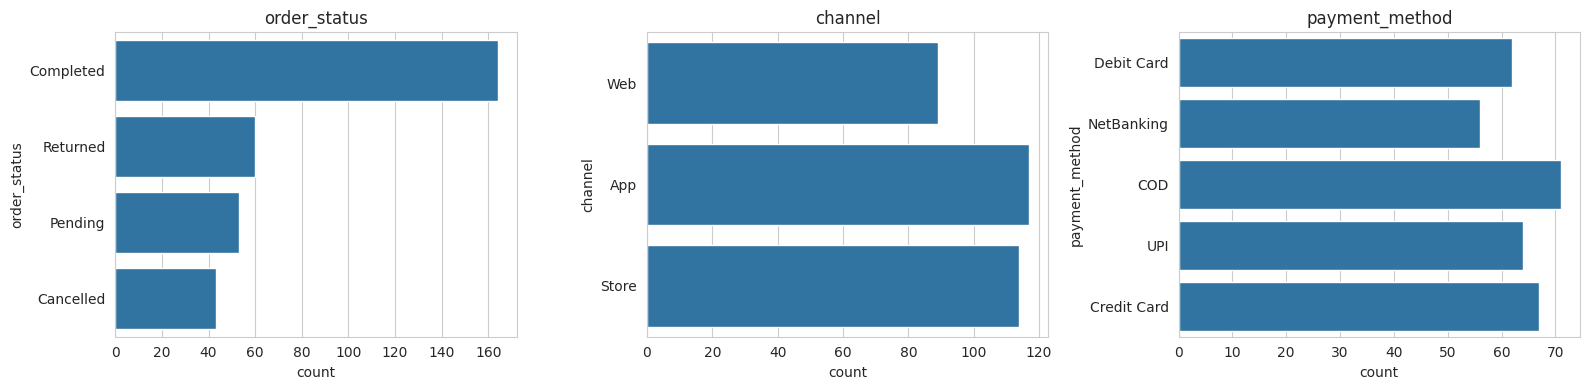

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(data=df, y='order_status', order=df['order_status'].value_counts().index, ax=ax[0])
sns.countplot(data=df, y='channel', order=['Web', 'App', 'Store'], ax=ax[1])
sns.countplot(data=df, y='payment_method', ax=ax[2])
ax[0].set_title('order_status')
ax[1].set_title('channel')
ax[2].set_title('payment_method')
plt.tight_layout()
plt.show()

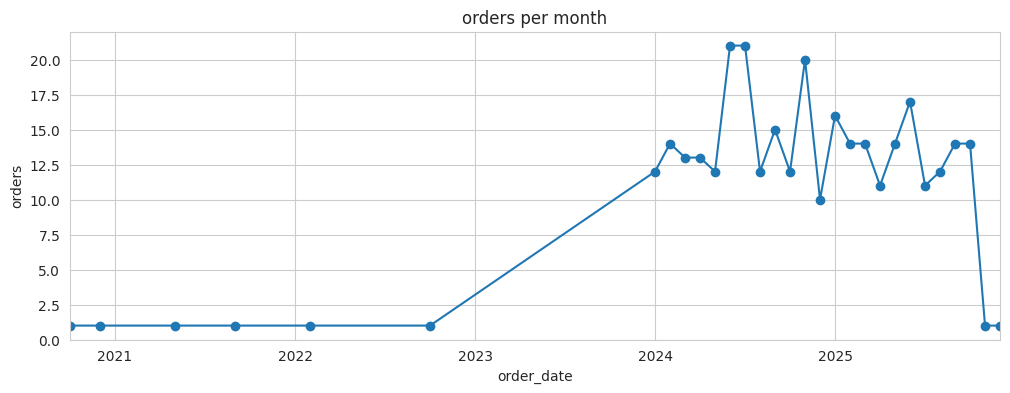

In [25]:
monthly = df.groupby(df['order_date'].dt.to_period('M')).size()
plt.figure(figsize=(12, 4))
monthly.plot(marker='o')
plt.title('orders per month')
plt.ylabel('orders')
plt.show()

In [26]:
pd.crosstab(df['channel'], df['order_status'])

order_status,Cancelled,Completed,Pending,Returned
channel,,,,
App,13,63,19,22
Store,17,53,19,25
Web,13,48,15,13


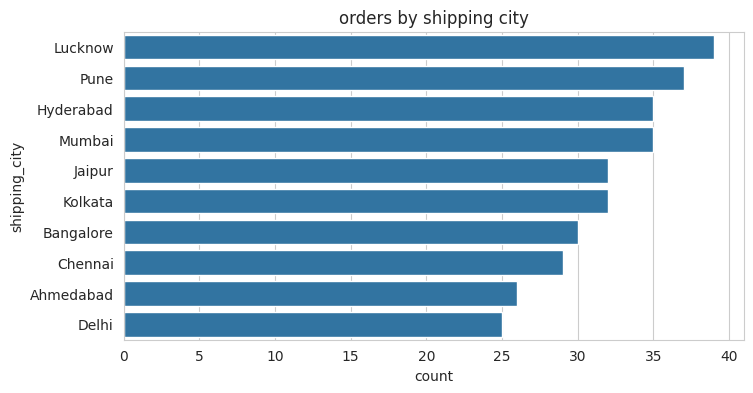

In [27]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, y='shipping_city', order=df['shipping_city'].value_counts().index)
plt.title('orders by shipping city')
plt.show()

In [28]:
df.to_csv('orders_clean.csv', index=False)
df.head()

,order_id,customer_id,order_date,order_status,payment_method,channel,promo_code,shipping_city,has_promo,order_ambiguous,date_outlier,customer_orphan,before_signup,no_items
0,O00140,C0112,2025-09-06,Completed,Debit Card,Web,PROMO19,Chennai,True,True,False,False,False,False
1,O00225,C0066,2025-10-14,Completed,NetBanking,Web,NaN,Delhi,False,False,False,False,False,False
2,O00188,C0082,2024-10-24,Pending,COD,App,NaN,Hyderabad,False,False,False,False,False,False
3,O00183,C0114,2024-07-30,Pending,UPI,App,NaN,Ahmedabad,False,False,False,False,False,False
4,O00233,C0078,2025-02-26,Completed,Credit Card,Web,PROMO17,Hyderabad,True,False,False,False,False,False
